CKM syndrome staging in US adults with obesity-related cancer, NHANES 2017-March 2020 (P_ files)

Run top to bottom. PREVENT needs one detour the first time: the notebook writes prevent_input.csv and prevent_input_capped.csv, you run the R preventr script (save it as run_prevent.R next to this notebook) on both (outputs prevent_output.csv with SEQN, prevent10 and prevent_output_capped.csv with SEQN, prevent10_capped), then continue. Once those files exist, Run All works in one pass.

NHANES files needed in DATA_DIR: P_DEMO, P_BPXO, P_BMX, P_ALB_CR, P_BIOPRO, P_GHB, P_GLU, P_HDL, P_TCHOL, P_TRIGLY, P_BPQ, P_DIQ, P_MCQ, P_SMQ, P_KIQ_U. P_OGTT is not published for this cycle and is skipped.

In [1]:
# settings and paths
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from scipy.stats import chi2_contingency

DATA_DIR = os.path.expanduser("~/Desktop/NHANES")
OUT_DIR = os.path.expanduser("~/Desktop")
W, STR, PSU = "WTMECPRP", "SDMVSTRA", "SDMVPSU"

import sys, sklearn
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| statsmodels", sm.__version__, "| scipy", __import__("scipy").__version__,
      "| sklearn", sklearn.__version__)

python 3.13.5 | pandas 2.2.3 | numpy 2.1.3 | statsmodels 0.14.4 | scipy 1.15.3 | sklearn 1.6.1


In [2]:
# load NHANES files
def read(name, required=True):
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        if required:
            raise FileNotFoundError(path)
        print("skipped", name)
        return None
    return pd.read_sas(path, format="xport", encoding="utf-8")

demo   = read("P_DEMO.XPT")
bpxo   = read("P_BPXO.XPT")
bmx    = read("P_BMX.XPT")
alb_cr = read("P_ALB_CR.XPT")
biopro = read("P_BIOPRO.XPT")
ghb    = read("P_GHB.XPT")
glu    = read("P_GLU.XPT")
hdl    = read("P_HDL.XPT")
tchol  = read("P_TCHOL.XPT")
trigly = read("P_TRIGLY.XPT")
bpq    = read("P_BPQ.XPT")
diq    = read("P_DIQ.XPT")
mcq    = read("P_MCQ.XPT")
smq    = read("P_SMQ.XPT")
kiq    = read("P_KIQ_U.XPT")
cbc    = read("P_CBC.XPT", required=False)      # haemoglobin, for the HbA1c set-aside
ferr   = read("P_FERTIN.XPT", required=False)   # ferritin, for the HbA1c set-aside
crp    = read("P_HSCRP.XPT", required=False)    # hs-CRP (mg/L), sets the ferritin cut-off
upreg  = read("P_UCPREG.XPT", required=False)   # urine pregnancy test

In [3]:
# merge into one dataframe, adults 20 and older
df = demo[["SEQN", "RIDAGEYR", "RIAGENDR", "RIDRETH3", "RIDEXPRG", W, STR, PSU]].copy()

parts = [
    (bpxo,   ["SEQN", "BPXOSY1", "BPXOSY2", "BPXOSY3", "BPXODI1", "BPXODI2", "BPXODI3"]),
    (bmx,    ["SEQN", "BMXBMI", "BMXWAIST"]),
    (alb_cr, ["SEQN", "URXUMA", "URXUCR", "URDACT"]),
    (biopro, ["SEQN", "LBXSCR"]),
    (ghb,    ["SEQN", "LBXGH"]),
    (glu,    ["SEQN", "LBXGLU"]),
    (hdl,    ["SEQN", "LBDHDD"]),
    (tchol,  ["SEQN", "LBXTC"]),
    (trigly, ["SEQN", "LBXTR", "LBDLDL"]),
    (bpq,    ["SEQN", "BPQ020", "BPQ050A", "BPQ100D"]),
    (diq,    ["SEQN", "DIQ010"] + (["DIQ160"] if "DIQ160" in diq.columns else [])),
    (mcq,    ["SEQN", "MCQ160B", "MCQ160C", "MCQ160D", "MCQ160E", "MCQ160F",
              "MCQ220", "MCQ230A", "MCQ230B", "MCQ230C", "MCQ230D"]
             + [c for c in ["MCQ510C"] if c in mcq.columns]),
    (smq,    ["SEQN", "SMQ020", "SMQ040"]),
    (kiq,    ["SEQN", "KIQ025"]),
]
for t, c in [(cbc, "LBXHGB"), (ferr, "LBXFER"), (crp, "LBXHSCRP"), (upreg, "URXPREG")]:
    if t is not None and c in t.columns:
        parts.append((t, ["SEQN", c]))

for t, cols in parts:
    df = df.merge(t[cols], on="SEQN", how="left")
for c in ["DIQ160", "LBXHGB", "LBXFER", "LBXHSCRP", "URXPREG", "RIDEXPRG", "MCQ510C"]:
    if c not in df.columns:
        df[c] = np.nan

df = df[df["RIDAGEYR"] >= 20].copy()
print("adults 20+:", len(df))

adults 20+: 9232


In [4]:
# UACR (mg/g, NHANES URDACT = albumin ug/mL / creatinine mg/dL * 100), eGFR (CKD-EPI 2021), mean blood pressure
df["UACR"] = df["URDACT"]
print("max gap vs albumin / creatinine * 100:", round(float((df["URXUMA"] / df["URXUCR"] * 100 - df["UACR"]).abs().max()), 3))

def calc_egfr(row):
    scr, age, sex = row["LBXSCR"], row["RIDAGEYR"], row["RIAGENDR"]
    if pd.isna(scr) or pd.isna(age):
        return np.nan
    kappa, alpha = (0.7, -0.241) if sex == 2 else (0.9, -0.302)
    ratio = scr / kappa
    egfr = 142 * (min(ratio, 1) ** alpha) * (max(ratio, 1) ** -1.200) * (0.9938 ** age)
    return egfr * 1.012 if sex == 2 else egfr

df["eGFR"] = df.apply(calc_egfr, axis=1)
df["SBP_mean"] = df[["BPXOSY1", "BPXOSY2", "BPXOSY3"]].mean(axis=1)
df["DBP_mean"] = df[["BPXODI1", "BPXODI2", "BPXODI3"]].mean(axis=1)

max gap vs albumin / creatinine * 100: 0.005


In [5]:
# write PREVENT inputs (age 30-79, no CVD, complete inputs), plain and range-capped
# sbp is the mean of up to three readings, same as staging
p = pd.DataFrame({"SEQN": df["SEQN"]})
p["age"]     = df["RIDAGEYR"]
p["sex"]     = np.where(df["RIAGENDR"] == 2, "female", "male")
p["sbp"]     = df["SBP_mean"]
p["total_c"] = df["LBXTC"]
p["hdl_c"]   = df["LBDHDD"]
p["bmi"]     = df["BMXBMI"]
p["egfr"]    = df["eGFR"]
p["bp_tx"]   = (df["BPQ050A"] == 1).astype(int)
p["statin"]  = (df["BPQ100D"] == 1).astype(int)
p["dm"]      = ((df["DIQ010"] == 1) | (df["LBXGH"] >= 6.5) | (df["LBXGLU"] >= 126)).astype(int)
p["smoking"] = ((df["SMQ020"] == 1) & (df["SMQ040"].isin([1, 2]))).astype(int)

cvd = df[["MCQ160B", "MCQ160C", "MCQ160E", "MCQ160F"]].eq(1).any(axis=1)
need = ["age", "sbp", "total_c", "hdl_c", "bmi", "egfr"]
eligible = p["age"].between(30, 79) & ~cvd & p[need].notna().all(axis=1)
print("eligible for PREVENT:", eligible.sum(), "of", len(p))

def write_if_changed(frame, path):
    # leave the file (and its timestamp) alone if the content is identical, so the R outputs stay newer than the inputs
    new = frame.to_csv(index=False)
    if os.path.exists(path) and open(path).read() == new:
        return
    open(path, "w").write(new)

p_ok = p[eligible].copy()
write_if_changed(p_ok, os.path.join(OUT_DIR, "prevent_input.csv"))

ranges = {"sbp": (90, 200), "total_c": (130, 320), "hdl_c": (20, 100), "bmi": (18.5, 40)}
p_cap = p_ok.copy()
for c, (lo, hi) in ranges.items():
    p_cap[c] = p_cap[c].clip(lo, hi)
write_if_changed(p_cap, os.path.join(OUT_DIR, "prevent_input_capped.csv"))

eligible for PREVENT: 4952 of 9232


Detour: run the R preventr script on prevent_input.csv and prevent_input_capped.csv, then continue below.

In [6]:
# merge PREVENT 10-year total CVD risk
f_in = os.path.join(OUT_DIR, "prevent_input.csv")
f_main = os.path.join(OUT_DIR, "prevent_output.csv")
if not os.path.exists(f_main):
    raise FileNotFoundError("run the R preventr script on prevent_input.csv first: " + f_main)
if os.path.getmtime(f_main) < os.path.getmtime(f_in):
    raise RuntimeError("prevent_output.csv is older than prevent_input.csv, rerun the R script before continuing")

pr = pd.read_csv(f_main)[["SEQN", "prevent10"]]
df = df.drop(columns=["prevent10", "prevent_high"], errors="ignore").merge(pr, on="SEQN", how="left")
df["prevent_high"] = (df["prevent10"] >= 0.20).fillna(False)
print("PREVENT >= 20%:", int(df["prevent_high"].sum()))

PREVENT >= 20%: 301


In [7]:
# CKM staging, following the lab's All of Us definition wherever NHANES can carry it. Anything not measured counts as absent, so staging is a floor.
# Stage 3 routes built: KDIGO very high, PREVENT >= 20%, kidney failure (eGFR < 15 or dialysis), coronary code alone (subclinical).
# Not measurable in NHANES: NT-proBNP/BNP, troponin, LVEF, PAD/ABI, AF, revascularisation, TIA, diagnosis codes, OGTT (no file 2017-Mar 2020),
# and confirmation of BP, eGFR or UACR on a second date (NHANES is one visit). Glucose and triglycerides exist only in the fasting subsample.
def ckm_components(row):
    ge = lambda c, v: pd.notna(row[c]) and row[c] >= v
    lt = lambda c, v: pd.notna(row[c]) and row[c] < v
    asian = row["RIDRETH3"] == 6
    male = row["RIAGENDR"] == 1
    wc_cut = (90.0 if asian else 102.0) if male else (80.0 if asian else 88.0)
    bmi_cut = 23.0 if asian else 25.0
    pregnant = row["RIDEXPRG"] == 1 or row["URXPREG"] == 1

    # HbA1c set-aside: pregnancy, anaemia (Hb < 12 F / < 13 M), iron deficiency (ferritin < 15, or < 70 if hs-CRP > 5 mg/L),
    # dialysis, kidney failure (eGFR < 15)
    ferr_cut = 70 if (pd.notna(row["LBXHSCRP"]) and row["LBXHSCRP"] > 5) else 15
    a1c_aside = (pregnant or lt("LBXHGB", 12 if not male else 13) or lt("LBXFER", ferr_cut)
                 or row["KIQ025"] == 1 or lt("eGFR", 15)
                 or row["MCQ510C"] == 3)                      # liver cirrhosis, a chronic set-aside condition
    # the set-aside applies to diabetes by value only; the Stage 1 prediabetes band reads HbA1c as recorded
    a1c_pre = pd.notna(row["LBXGH"]) and 5.7 <= row["LBXGH"] < 6.5
    a1c_dm = (not a1c_aside) and ge("LBXGH", 6.5)
    # a fasting glucose counts toward diabetes only outside a pregnancy
    fpg_dm = (not pregnant) and ge("LBXGLU", 126)

    # Stage 1 by measurement only: the guideline defines adiposity by BMI and waist, and NHANES has no recorded obesity diagnosis
    stage1 = (ge("BMXBMI", bmi_cut) or ge("BMXWAIST", wc_cut) or a1c_pre
              or (ge("LBXGLU", 100) and lt("LBXGLU", 126)) or row["DIQ160"] == 1)

    # diabetes: self-report, or two of the tests (HbA1c not set aside, fasting glucose outside pregnancy) at the diabetes cut-off
    dm_one_test = (a1c_dm or fpg_dm) and not (a1c_dm and fpg_dm)
    t2d = row["DIQ010"] == 1 or (a1c_dm and fpg_dm)

    # pressure by value (not in pregnancy) or medication; the metabolic-syndrome component reads it the same way
    bp_val = (not pregnant) and (ge("SBP_mean", 130) or ge("DBP_mean", 80))
    bp_med = row["BPQ050A"] == 1
    bp_component = bp_val or bp_med
    htn = row["BPQ020"] == 1 or bp_component
    tg_high = ge("LBXTR", 150)
    hdl_low = lt("LBDHDD", 40 if male else 50)
    mets = sum([ge("BMXWAIST", wc_cut), tg_high, hdl_low, ge("LBXGLU", 100), bp_component]) >= 3
    ckd = lt("eGFR", 60) or ge("UACR", 30)
    stage2 = t2d or htn or tg_high or mets or ckd

    egfr, uacr = row["eGFR"], row["UACR"]
    kdigo_vh = False
    if pd.notna(egfr):
        if egfr < 30:
            kdigo_vh = True                                    # G4 / G5
        elif egfr < 45 and pd.notna(uacr) and uacr >= 30:
            kdigo_vh = True                                    # G3b with A2 or A3
        elif egfr < 60 and pd.notna(uacr) and uacr > 300:
            kdigo_vh = True                                    # G3a with A3 (> 300)
    dialysis = row["KIQ025"] == 1
    kidney_failure = dialysis or lt("eGFR", 15)
    prevent_high = bool(row["prevent_high"]) if pd.notna(row.get("prevent_high", np.nan)) else False

    hf, mi, stroke = row["MCQ160B"] == 1, row["MCQ160E"] == 1, row["MCQ160F"] == 1
    chd, angina = row["MCQ160C"] == 1, row["MCQ160D"] == 1
    # Stage 4: heart failure, MI, stroke, or angina (coronary code with support, or angina reported alone).
    # The lab has no rule for angina reported without a coronary code (NHANES asks them separately), so the 2026 guideline applies:
    # stable or unstable angina is clinical ASCVD, Stage 4.
    stage4 = hf or mi or stroke or angina
    # Route 7: a coronary code with no other clinical CVD and none of the support is subclinical, Stage 3
    chd_alone = chd and not (angina or mi or hf or stroke)
    stage3 = kdigo_vh or kidney_failure or prevent_high or chd_alone

    return dict(stage1=stage1, stage2=stage2, stage3=stage3, stage4=stage4,
                kdigo_vh=kdigo_vh, dialysis=dialysis, kidney_failure=kidney_failure, prevent_high=prevent_high,
                chd_alone=chd_alone, cirrhosis=row["MCQ510C"] == 3, angina_alone=angina and not (chd or mi or hf or stroke),
                dm_one_test=dm_one_test, a1c_aside=a1c_aside, pregnant=pregnant)

def classify_ckm(row):
    c = ckm_components(row)
    if c["stage4"]: return 4
    if c["stage3"]: return 3
    if c["stage2"]: return 2
    if c["stage1"]: return 1
    return 0

df["CKM_Stage"] = df.apply(classify_ckm, axis=1)
df["adv"] = df["CKM_Stage"].isin([3, 4]).astype(float)

w = df[W].fillna(0)
dist = pd.DataFrame({"n": df["CKM_Stage"].value_counts().sort_index(),
                     "weighted %": [round(100 * w[df["CKM_Stage"] == k].sum() / w.sum(), 1) for k in range(5)]})
print(dist)
print("advanced CKM (stage 3-4), weighted: %.1f%%" % (100 * w[df["adv"] == 1].sum() / w.sum()))
comp0 = pd.DataFrame(list(df.apply(ckm_components, axis=1)), index=df.index)
lone4 = (df["CKM_Stage"] == 4) & ~(comp0["stage1"] | comp0["stage2"] | comp0["stage3"])
print("stage 4 with no other CKM criterion (still staged 4):", int(lone4.sum()))

# what the lab rules changed or could not confirm (unweighted counts)
print("coronary code alone, staged 3 (subclinical):", int(comp0["chd_alone"].sum()))
print("angina reported alone, staged 4 by the guideline (no lab rule):", int(comp0["angina_alone"].sum()))
print("cirrhosis reported:", int(comp0["cirrhosis"].sum()))
print("HbA1c set aside:", int(comp0["a1c_aside"].sum()), "| pregnant:", int(comp0["pregnant"].sum()))
print("one diabetes-range test only, not confirmed (HbA1c >= 6.5 or fasting glucose >= 126, not both, no self-report):",
      int((comp0["dm_one_test"] & (df["DIQ010"] != 1)).sum()))

              n  weighted %
CKM_Stage                  
0          1068        11.0
1          2122        28.1
2          4498        47.9
3           470         4.1
4          1074         8.8
advanced CKM (stage 3-4), weighted: 13.0%
stage 4 with no other CKM criterion (still staged 4): 35
coronary code alone, staged 3 (subclinical): 102
angina reported alone, staged 4 by the guideline (no lab rule): 71
cirrhosis reported: 34
HbA1c set aside: 1613 | pregnant: 87
one diabetes-range test only, not confirmed (HbA1c >= 6.5 or fasting glucose >= 126, not both, no self-report): 278


In [8]:
# obesity-related cancer groups (IARC sites identifiable in NHANES)
IARC_SITES = {16: "Colon", 31: "Rectum", 22: "Liver", 18: "Gallbladder", 29: "Pancreas",
              19: "Kidney", 37: "Thyroid", 38: "Uterus", 28: "Ovary"}
BREAST = 14
cancer_cols = ["MCQ230A", "MCQ230B", "MCQ230C"]
codes = df[cancer_cols].apply(lambda r: set(int(x) for x in r.dropna()), axis=1)

df["iarc_primary"] = [int(any(c in IARC_SITES for c in s) or (BREAST in s and a >= 55))
                      for s, a in zip(codes, df["RIDAGEYR"])]
df["iarc_all_breast"] = [int(any(c in IARC_SITES or c == BREAST for c in s)) for s in codes]
df["iarc_plus_eso_stomach"] = [int(p == 1 or any(c in (17, 35) for c in s))
                               for s, p in zip(codes, df["iarc_primary"])]
print(df["iarc_primary"].sum(), df["iarc_all_breast"].sum(), df["iarc_plus_eso_stomach"].sum())

# comparison groups: survivors, other-cancer survivors, no cancer. Ambiguous codes are left out.
AMBIG = {39, 33, 77, 99}
is_obs = df["iarc_primary"].eq(1)
overlap = df["iarc_all_breast"].eq(1) | df["iarc_plus_eso_stomach"].eq(1)
ambig = codes.apply(lambda s: bool(s & AMBIG))
ever = df["MCQ220"].eq(1)

df["grp"] = pd.Series(np.nan, index=df.index, dtype=object)
df.loc[df["MCQ220"].eq(2), "grp"] = "none"
df.loc[ever & ~is_obs & ~overlap & ~ambig, "grp"] = "other"
df.loc[ever & is_obs, "grp"] = "obesity"
df["has_prostate"] = codes.apply(lambda s: 30 in s)
df["has_breast"] = codes.apply(lambda s: BREAST in s)
df["iarc"] = is_obs

print(df["grp"].value_counts(dropna=False).to_dict())
print("adults without obesity-related cancer:", int((~is_obs).sum()))

# covariates used below
df["age10"] = df["RIDAGEYR"] / 10
df["age10_sq"] = df["age10"] ** 2
df["female"] = (df["RIAGENDR"] == 2).astype(float)
df["obese"] = (df["BMXBMI"] >= 30).astype(float)
df["e_main"] = is_obs.astype(float)
df["e_obs"] = df["grp"].eq("obesity").astype(float)
df["e_other"] = df["grp"].eq("other").astype(float)
race_d = pd.get_dummies(df["RIDRETH3"], prefix="r", drop_first=True).astype(float)
df = pd.concat([df, race_d], axis=1)
RACE = list(race_d.columns)
AS, ASO, ASR = ["RIDAGEYR", "female"], ["RIDAGEYR", "female", "obese"], ["RIDAGEYR", "female"] + RACE
allm = pd.Series(True, index=df.index)
d = df

338 357 353
{'none': 8222, 'other': 461, 'obesity': 338, nan: 211}
adults without obesity-related cancer: 8894


In [9]:
# design-based helpers: Taylor linearization with strata and PSU
def _var_from_z(z, data):
    t = pd.DataFrame({"z": z, "s": data[STR].values, "p": data[PSU].values}).groupby(["s", "p"])["z"].sum()
    v, dof = 0.0, 0
    for s, g in t.groupby(level=0):
        n = len(g)
        dof += n - 1
        if n > 1:
            v += n / (n - 1) * ((g - g.mean()) ** 2).sum()
    return v, dof

def prevalence_se(data, mask, y="adv"):
    m = mask.values.astype(float)
    wt = data[W].values
    yv = data[y].values.astype(float)
    m = m * ~np.isnan(yv)
    yv = np.nan_to_num(yv)
    den = (wt * m).sum()
    p = (wt * m * yv).sum() / den
    v, dof = _var_from_z(m * wt * (yv - p) / den, data)
    return p * 100, np.sqrt(v) * 100, dof, int(m.sum())

def prevalence(data, mask, y="adv"):
    p, se, dof, n = prevalence_se(data, mask, y)
    q = stats.t.ppf(0.975, dof)
    return p, max(0, p - q * se), min(100, p + q * se), n

def design_logit(data, mask, exp, covars, weighted=True, y="adv"):
    sub = data[mask & data[y].notna()]
    X = sub[[exp] + covars].astype(float)
    X.insert(0, "const", 1.0)
    wt = sub[W].values if weighted else np.ones(len(sub))
    fit = sm.GLM(sub[y].astype(float), X, family=sm.families.Binomial(), freq_weights=wt).fit()
    mu = fit.predict(X).values
    U = X.values * ((sub[y].values - mu) * wt)[:, None]
    full = np.zeros((len(data), X.shape[1]))
    full[data.index.get_indexer(sub.index)] = U
    g = pd.DataFrame(full).assign(s=data[STR].values, p=data[PSU].values).groupby(["s", "p"]).sum()
    meat, dof = np.zeros((X.shape[1],) * 2), 0
    for s, gg in g.groupby(level=0):
        n = len(gg)
        dof += n - 1
        if n > 1:
            c = gg.values - gg.values.mean(0)
            meat += n / (n - 1) * c.T @ c
    bread = np.linalg.inv((X.values * (wt * mu * (1 - mu))[:, None]).T @ X.values)
    cov = bread @ meat @ bread
    b, se = fit.params[exp], np.sqrt(cov[1, 1])
    q = stats.t.ppf(0.975, dof)
    pval = 2 * (1 - stats.t.cdf(abs(b / se), dof))
    return np.exp(b), np.exp(b - q * se), np.exp(b + q * se), len(sub), pval

In [10]:
# stage distribution with design-based 95% CIs
for k in range(5):
    df[f"s{k}"] = (df["CKM_Stage"] == k).astype(float)

groups = {"All adults": allm,
          "Obesity-related cancer survivors": df["iarc"],
          "Adults without obesity-related cancer": ~df["iarc"],
          "No cancer": df["grp"].eq("none"),
          "Other cancer": df["grp"].eq("other")}
rows = []
for gname, dom in groups.items():
    for label, y in [("Stage 0", "s0"), ("Stage 1", "s1"), ("Stage 2", "s2"), ("Stage 3", "s3"),
                     ("Stage 4", "s4"), ("Advanced (3+4)", "adv")]:
        pct, lo, hi, n = prevalence(df, dom, y)
        rows.append({"Group": gname, "Stage": label, "n_group": int(dom.sum()),
                     "Weighted %": round(pct, 1), "CI_lo": round(lo, 1), "CI_hi": round(hi, 1)})
stage_ci = pd.DataFrame(rows)
print(stage_ci.pivot(index="Stage", columns="Group", values="Weighted %").round(1).to_string())
print()
for g in ["All adults", "Obesity-related cancer survivors", "Adults without obesity-related cancer"]:
    print(g)
    print(stage_ci[stage_ci.Group == g][["Stage", "n_group", "Weighted %", "CI_lo", "CI_hi"]].to_string(index=False))
    print()
print(stage_ci[stage_ci.Stage == "Advanced (3+4)"].to_string(index=False))
stage_ci.to_csv(os.path.join(OUT_DIR, "stage_ci.csv"), index=False)

# unweighted chi-square, survivors vs everyone else (descriptive only)
ct = pd.crosstab(df["iarc"], df["CKM_Stage"])
chi2, pchi, dof_chi, _ = chi2_contingency(ct)
print("\nunweighted chi-square, survivors vs others: chi2=%.1f, df=%d, p=%.3g" % (chi2, dof_chi, pchi))

Group           Adults without obesity-related cancer  All adults  No cancer  Obesity-related cancer survivors  Other cancer
Stage                                                                                                                       
Advanced (3+4)                                   12.3        13.0       10.8                              29.4          31.0
Stage 0                                          11.3        11.0       11.7                               5.1           8.0
Stage 1                                          28.7        28.1       29.6                              11.9          14.0
Stage 2                                          47.7        47.9       48.0                              53.6          47.0
Stage 3                                           4.0         4.1        3.4                               8.5          12.0
Stage 4                                           8.4         8.8        7.4                              20.9          19.0


In [11]:
# weighted stage distribution by sex and by race/ethnicity (row %)
sex = df["RIAGENDR"].map({1: "Male", 2: "Female"})
race_map = {1: "Mexican American", 2: "Other Hispanic", 3: "NH White", 4: "NH Black", 6: "NH Asian", 7: "Other/Multiracial"}
race = df["RIDRETH3"].map(race_map)
for name, var in [("sex", sex), ("race/ethnicity", race)]:
    tab = df.pivot_table(index=var, columns="CKM_Stage", values=W, aggfunc="sum").fillna(0)
    print("weighted stage % by", name)
    print((tab.div(tab.sum(axis=1), axis=0) * 100).round(1).to_string(), "\n")

weighted stage % by sex
CKM_Stage     0     1     2    3    4
RIAGENDR                             
Female     12.9  28.3  47.6  3.2  8.0
Male        9.0  27.9  48.2  5.1  9.7 

weighted stage % by race/ethnicity
CKM_Stage             0     1     2    3     4
RIDRETH3                                      
Mexican American    8.3  39.8  46.2  2.1   3.6
NH Asian           11.3  34.5  46.6  3.5   4.2
NH Black            9.2  25.7  51.6  4.2   9.4
NH White           11.9  25.9  47.8  4.5  10.0
Other Hispanic     11.5  33.1  46.2  2.8   6.4
Other/Multiracial   8.2  26.9  47.3  6.0  11.6 



In [12]:
# Table 1: weighted characteristics, all adults vs survivors
def wmean_sd(x, wt):
    m = np.average(x, weights=wt)
    return m, np.sqrt(np.average((x - m) ** 2, weights=wt))

def wmedian_iqr(x, wt):
    o = np.argsort(x)
    x, wt = x[o], wt[o]
    cw = np.cumsum(wt) / wt.sum()
    q = lambda p: x[np.searchsorted(cw, p)]
    return q(0.5), q(0.25), q(0.75)

age_bins = pd.cut(df["RIDAGEYR"], [19, 39, 59, 200], labels=["20-39", "40-59", "60+"])
cat_vars = {"Age group, y": age_bins, "Sex": sex, "Race/ethnicity": race}
cont_vars = {"BMI, kg/m2": "BMXBMI", "HbA1c, %": "LBXGH", "Total cholesterol, mg/dL": "LBXTC", "eGFR": "eGFR"}

cols_out = []
for gname, dom in [("All adults", allm), ("Obesity-related cancer survivors", df["iarc"])]:
    sub = df[dom]
    col = [("N (unweighted)", f"{len(sub):,}")]
    for vname, s in cat_vars.items():
        s = s[dom]
        tot = sub.loc[s.notna(), W].sum()
        col.append((vname, ""))
        levels = s.cat.categories if hasattr(s, "cat") else s.dropna().unique()
        for lvl in levels:
            msk = s == lvl
            col.append((f"   {lvl}", f"{int(msk.sum())} ({sub.loc[msk, W].sum() / tot * 100:.1f}%)"))
    for vname, c in cont_vars.items():
        ok = sub[c].notna()
        m, sd = wmean_sd(sub.loc[ok, c].values, sub.loc[ok, W].values)
        col.append((vname, f"{m:.1f} ({sd:.1f})"))
    ok = sub["UACR"].notna()
    med, q1, q3 = wmedian_iqr(sub.loc[ok, "UACR"].values, sub.loc[ok, W].values)
    col.append(("UACR, mg/g, median (IQR)", f"{med:.1f} ({q1:.1f}-{q3:.1f})"))
    cols_out.append(pd.DataFrame(col, columns=["Characteristic", gname]).set_index("Characteristic"))

table1 = cols_out[0].join(cols_out[1], how="outer")
table1 = table1.reindex(cols_out[0].index.tolist() + [i for i in cols_out[1].index if i not in cols_out[0].index])
print(table1.to_string())
table1.to_csv(os.path.join(OUT_DIR, "table1.csv"))

                              All adults Obesity-related cancer survivors
Characteristic                                                           
N (unweighted)                     9,232                              338
Age group, y                                                             
   20-39                    2799 (36.0%)                        10 (3.7%)
   40-59                    3011 (34.2%)                       79 (19.3%)
   60+                      3422 (29.8%)                      249 (77.0%)
Sex                                                                      
   Female                   4753 (51.9%)                      264 (85.8%)
   Male                     4479 (48.1%)                       74 (14.2%)
Race/ethnicity                                                           
   NH Asian                  1120 (6.0%)                        21 (3.0%)
   Other Hispanic             940 (7.7%)                        28 (4.7%)
   NH White                 3217 (62.6

In [13]:
# cancer sites among survivors: n, share of survivors, advanced CKM
SITES = {14: "Breast (age >=55)", 16: "Colon", 38: "Uterus", 37: "Thyroid", 19: "Kidney",
         28: "Ovary", 31: "Rectum", 22: "Liver", 29: "Pancreas", 18: "Gallbladder"}
coh_w = df.loc[df["iarc"], W].sum()
rows = []
for c, nm in SITES.items():
    mk = codes.apply(lambda s: c in s)
    if c == 14:
        mk = mk & (df["RIDAGEYR"] >= 55)
    mk = mk & df["iarc"]
    p, lo, hi, n = prevalence(df, mk)
    rows.append({"Site": nm, "n": n, "Share of survivors %": round(df.loc[mk, W].sum() / coh_w * 100, 1),
                 "Advanced CKM %": f"{p:.1f} ({lo:.1f}-{hi:.1f})" if n >= 30 else "not estimated",
                 "Note": "n<30" if n < 30 else ""})
site_tbl = pd.DataFrame(rows).sort_values("n", ascending=False)
print(site_tbl.to_string(index=False))
print("participants can have more than one site, so n sums above", int(df["iarc"].sum()))
site_tbl.to_csv(os.path.join(OUT_DIR, "site_table.csv"), index=False)

             Site   n  Share of survivors %   Advanced CKM % Note
Breast (age >=55) 139                  47.9 30.0 (14.0-46.0)     
            Colon  74                  16.0  24.2 (8.5-39.9)     
           Uterus  44                  16.3 34.7 (20.5-48.9)     
          Thyroid  34                   8.7  32.4 (0.0-68.2)     
           Kidney  28                   5.6    not estimated n<30
            Ovary  22                   8.5    not estimated n<30
           Rectum  10                   1.1    not estimated n<30
            Liver   5                   0.9    not estimated n<30
         Pancreas   5                   0.5    not estimated n<30
      Gallbladder   1                   0.3    not estimated n<30
participants can have more than one site, so n sums above 338


In [14]:
# advanced CKM by group and odds ratios, weighted and unweighted
rows = []
for g, label in [("obesity", "Obesity-related cancer"), ("other", "Other cancer"), ("none", "No cancer")]:
    mk = df["grp"].eq(g)
    p, lo, hi, n = prevalence(df, mk)
    rows.append({"Group": label, "n": n, "Weighted adv CKM %": round(p, 1), "95% CI": f"{lo:.1f}-{hi:.1f}",
                 "Unweighted %": round(df.loc[mk, "adv"].mean() * 100, 1)})
prev_groups = pd.DataFrame(rows)
print(prev_groups.to_string(index=False))

specs = [
    ("Survivors vs everyone else", "e_main", allm, AS, "age, sex"),
    ("Survivors vs everyone else", "e_main", allm, ASO, "age, sex, obesity"),
    ("Survivors vs no cancer", "e_obs", df["grp"].isin(["obesity", "none"]), AS, "age, sex"),
    ("Survivors vs no cancer", "e_obs", df["grp"].isin(["obesity", "none"]), ASO, "age, sex, obesity"),
    ("Other cancer vs no cancer", "e_other", df["grp"].isin(["other", "none"]), AS, "age, sex"),
    ("Survivors vs other cancer", "e_obs", df["grp"].isin(["obesity", "other"]), AS, "age, sex"),
    ("Survivors vs other cancer", "e_obs", df["grp"].isin(["obesity", "other"]), ASO, "age, sex, obesity"),
    ("Survivors vs other cancer", "e_obs", df["grp"].isin(["obesity", "other"]), ASR, "age, sex, race/ethnicity"),
    ("Survivors vs other cancer, excl. prostate", "e_obs",
     df["grp"].eq("obesity") | (df["grp"].eq("other") & ~df["has_prostate"]), AS, "age, sex"),
]
rows = []
for label, exp, mk, cov, tag in specs:
    for wtd in (True, False):
        o, lo, hi, n, pv = design_logit(df, mk, exp, cov, weighted=wtd)
        rows.append({"Comparison": label, "Adjusted for": tag, "Weights": "weighted" if wtd else "unweighted",
                     "n": n, "OR": round(o, 2), "95% CI": f"{lo:.2f}-{hi:.2f}"})
or_tbl = pd.DataFrame(rows)
print()
print(or_tbl.to_string(index=False))

# unadjusted, age/sex, and age-squared models for survivors vs everyone else
rows = []
for name, cov in [("Unadjusted", []), ("Adjusted for age, sex", ["age10", "female"]),
                  ("Adjusted, age squared added", ["age10", "age10_sq", "female"])]:
    o, lo, hi, n, pv = design_logit(df, allm, "e_main", cov)
    rows.append({"Model": name, "OR": round(o, 4), "CI_lo": round(lo, 4), "CI_hi": round(hi, 4), "p": round(pv, 4)})
adj_tbl = pd.DataFrame(rows)
print()
print(adj_tbl.to_string(index=False))
prev_groups.to_csv(os.path.join(OUT_DIR, "prevalence_groups.csv"), index=False)
or_tbl.to_csv(os.path.join(OUT_DIR, "odds_ratios.csv"), index=False)
adj_tbl.to_csv(os.path.join(OUT_DIR, "adjusted_comparison.csv"), index=False)

                 Group    n  Weighted adv CKM %    95% CI  Unweighted %
Obesity-related cancer  338                29.4 19.5-39.4          31.1
          Other cancer  461                31.0 24.8-37.3          33.8
             No cancer 8222                10.8  9.5-12.1          14.7

                               Comparison             Adjusted for    Weights    n   OR    95% CI
               Survivors vs everyone else                 age, sex   weighted 9232 1.38 0.79-2.42
               Survivors vs everyone else                 age, sex unweighted 9232 1.22 0.97-1.54
               Survivors vs everyone else        age, sex, obesity   weighted 9232 1.35 0.79-2.33
               Survivors vs everyone else        age, sex, obesity unweighted 9232 1.21 0.95-1.54
                   Survivors vs no cancer                 age, sex   weighted 8560 1.40 0.81-2.43
                   Survivors vs no cancer                 age, sex unweighted 8560 1.21 0.96-1.52
                   Surviv

In [15]:
# exposure definition sensitivity
defs = {
    "Primary (breast at age >=55)":   (df["iarc_primary"].eq(1), allm),
    "All breast cancers counted":     (df["iarc_all_breast"].eq(1), allm),
    "Adding esophagus and stomach":   (df["iarc_plus_eso_stomach"].eq(1), allm),
    "Excluding all breast cancer":    (df["iarc_primary"].eq(1) & ~df["has_breast"], ~df["has_breast"]),
}
rows = []
for name, (expo, mk) in defs.items():
    df["e_tmp"] = expo.astype(float)
    pe, loe, hie, ne = prevalence(df, expo & mk)
    pc, loc, hic, nc = prevalence(df, ~expo & mk)
    o0, l0, h0, _, _ = design_logit(df, mk, "e_tmp", [])
    o1, l1, h1, _, _ = design_logit(df, mk, "e_tmp", AS)
    rows.append({"Definition": name, "n exposed": ne,
                 "Exposed adv %": f"{pe:.1f} ({loe:.1f}-{hie:.1f})",
                 "Comparison adv %": f"{pc:.1f} ({loc:.1f}-{hic:.1f})",
                 "Unadj OR": f"{o0:.2f} ({l0:.2f}-{h0:.2f})",
                 "Age/sex-adj OR": f"{o1:.2f} ({l1:.2f}-{h1:.2f})"})
sens_def = pd.DataFrame(rows)
print(sens_def.to_string(index=False))
sens_def.to_csv(os.path.join(OUT_DIR, "sensitivity_exposure.csv"), index=False)

                  Definition  n exposed    Exposed adv % Comparison adv %         Unadj OR   Age/sex-adj OR
Primary (breast at age >=55)        338 29.4 (19.5-39.4) 12.3 (10.9-13.8) 2.97 (1.81-4.85) 1.38 (0.79-2.42)
  All breast cancers counted        357 27.5 (18.4-36.6) 12.3 (10.9-13.8) 2.70 (1.69-4.30) 1.43 (0.82-2.48)
Adding esophagus and stomach        353 29.8 (19.9-39.6) 12.3 (10.9-13.7) 3.02 (1.86-4.91) 1.39 (0.80-2.41)
 Excluding all breast cancer        199 28.9 (21.3-36.5) 12.3 (10.9-13.8) 2.89 (1.99-4.20) 1.51 (0.96-2.38)


In [16]:
# direct age standardization to the 2000 US standard population (20-39, 40-59, 60-69, 70+), jackknife CIs
age_edges = [19, 39, 59, 69, 200]
age_labels = ["20-39", "40-59", "60-69", "70+"]
std_counts = np.array([282813, 265139, 73057, 92122], dtype=float)
std_w = std_counts / std_counts.sum()
da = df.dropna(subset=["RIDAGEYR", "RIAGENDR", W, "CKM_Stage", STR, PSU]).copy()
da["ageg"] = pd.cut(da["RIDAGEYR"], age_edges, labels=age_labels)
w0 = da[W].values
yv = da["adv"].values

def std_prev(wt, dom):
    out = 0.0
    for k, lab in enumerate(age_labels):
        ag = (da["ageg"] == lab).values
        den = (wt * dom * ag).sum()
        if den > 0:
            out += std_w[k] * (wt * dom * ag * yv).sum() / den
    return out * 100

doms = {"All adults": np.ones(len(da)),
        "Obesity-related cancer survivors": da["iarc"].values.astype(float),
        "Adults without obesity-related cancer": (~da["iarc"]).values.astype(float)}
npsu = da.groupby([STR, PSU]).ngroups
tc = stats.t.ppf(0.975, npsu - da[STR].nunique())
rows = []
for gname, dom in doms.items():
    est = std_prev(w0, dom)
    var = 0.0
    for h, sub in da.groupby(STR):
        psus = sub[PSU].unique()
        nh = len(psus)
        if nh < 2:
            continue
        in_h = (da[STR] == h).values
        reps = []
        for j in psus:
            wt = w0.copy()
            wt[in_h & (da[PSU] == j).values] = 0
            wt[in_h & (da[PSU] != j).values] *= nh / (nh - 1)
            reps.append(std_prev(wt, dom))
        var += (nh - 1) / nh * ((np.array(reps) - est) ** 2).sum()
    se = np.sqrt(var)
    rows.append({"Group": gname, "Age-standardized advanced CKM %": round(est, 1),
                 "CI_lo": round(est - tc * se, 1), "CI_hi": round(est + tc * se, 1)})
std_tbl = pd.DataFrame(rows)
print(std_tbl.to_string(index=False))
std_tbl.to_csv(os.path.join(OUT_DIR, "age_standardized.csv"), index=False)

                                Group  Age-standardized advanced CKM %  CI_lo  CI_hi
                           All adults                             11.5   10.6   12.4
     Obesity-related cancer survivors                             21.5   11.2   31.8
Adults without obesity-related cancer                             11.4   10.6   12.3


In [17]:
# Table 3: predictors of advanced CKM among survivors (robust SEs, no strata/PSU)
from scipy.stats import norm

ds = df[df["iarc"]].copy()
ds["race"] = pd.Categorical(ds["RIDRETH3"].map(race_map),
                            categories=["NH White", "Mexican American", "Other Hispanic", "NH Black", "NH Asian", "Other/Multiracial"])
cols = ["RIDAGEYR", "BMXBMI", "LBXGH", "LBXTC", "eGFR", "UACR"]
ds = ds.dropna(subset=cols + ["race", W, "adv"])
y = ds["adv"].values.astype(float)
print("N =", len(ds), "| advanced CKM events =", int(y.sum()))

def fit_t3(collapsed=True):
    if collapsed:
        race_X = pd.DataFrame({"non_white": (ds["race"] != "NH White").astype(int)}, index=ds.index)
    else:
        race_X = pd.get_dummies(ds["race"], drop_first=True).astype(int)
    X = sm.add_constant(pd.concat([ds[cols], ds[["female"]], race_X], axis=1).astype(float))
    Xv = X.values
    wt = (ds[W] / ds[W].mean()).values
    m = sm.GLM(y, Xv, family=sm.families.Binomial(), freq_weights=wt).fit()
    beta, mu = np.asarray(m.params), np.asarray(m.fittedvalues)
    A = np.linalg.inv((Xv * (wt * mu * (1 - mu))[:, None]).T @ Xv)
    scores = Xv * (wt * (y - mu))[:, None]
    n, k = Xv.shape
    se = np.sqrt(np.diag(A @ (scores.T @ scores) @ A * (n / (n - k))))
    out = pd.DataFrame({"OR": np.exp(beta), "CI_lo": np.exp(beta - 1.96 * se), "CI_hi": np.exp(beta + 1.96 * se),
                        "p": 2 * (1 - norm.cdf(np.abs(beta / se)))}, index=X.columns).round(3)
    return out.drop(index="const")

t3 = fit_t3(True)
t3_full = fit_t3(False)

scale = {"RIDAGEYR": (10, "Age, per 10 years"), "BMXBMI": (1, "BMI, per kg/m2"), "LBXGH": (1, "HbA1c, per 1%"),
         "LBXTC": (10, "Total cholesterol, per 10 mg/dL"), "eGFR": (10, "eGFR, per 10 mL/min/1.73 m2"),
         "UACR": (30, "UACR, per 30 mg/g"), "female": (1, "Female vs male"), "non_white": (1, "Non-White vs NH White")}
rows = []
for k, (pw, lab) in scale.items():
    r = t3.loc[k]
    rows.append({"Variable": lab, "OR": round(r.OR ** pw, 2), "CI_lo": round(r.CI_lo ** pw, 2),
                 "CI_hi": round(r.CI_hi ** pw, 2), "p": "<0.001" if r.p < 0.001 else round(r.p, 3)})
table3 = pd.DataFrame(rows)
print(table3.to_string(index=False))
table3.to_csv(os.path.join(OUT_DIR, "table3.csv"), index=False)
t3_full.to_csv(os.path.join(OUT_DIR, "table3_full_race.csv"))

N = 249 | advanced CKM events = 82
                       Variable   OR  CI_lo  CI_hi     p
              Age, per 10 years 0.96   0.57   1.61 0.887
                 BMI, per kg/m2 1.03   0.98   1.09 0.180
                  HbA1c, per 1% 1.87   1.25   2.80 0.002
Total cholesterol, per 10 mg/dL 0.90   0.82   0.99 0.037
    eGFR, per 10 mL/min/1.73 m2 0.69   0.54   0.87 0.002
              UACR, per 30 mg/g 1.09   0.91   1.31 0.274
                 Female vs male 1.20   0.42   3.49 0.732
          Non-White vs NH White 0.96   0.36   2.55 0.936


In [18]:
# stage 3 routes (a person can qualify through more than one)
comp = pd.DataFrame(list(df.apply(ckm_components, axis=1)), index=df.index)
s3 = df["CKM_Stage"] == 3
print("stage 3 n =", int(s3.sum()))
for c in ["kdigo_vh", "kidney_failure", "prevent_high", "chd_alone"]:
    print(f"  {c}: {int((comp[c] & s3).sum())}")
only_prevent = comp["prevent_high"] & ~comp["kdigo_vh"] & ~comp["kidney_failure"] & ~comp["chd_alone"]
print("  PREVENT only:", int((only_prevent & s3).sum()))

stage 3 n = 470
  kdigo_vh: 103
  kidney_failure: 27
  prevent_high: 296
  chd_alone: 102
  PREVENT only: 268


In [19]:
# sensitivity: complete case on the main lab and BP inputs (mostly selects the fasting subsample)
key_vars = ["BMXBMI", "LBXGH", "LBXGLU", "eGFR", "UACR", "BPXOSY1", "BPXODI1", "LBXTC", "LBDLDL", "LBDHDD", "LBXTR"]
dc = df.dropna(subset=key_vars)
cc_overall = prevalence(df, pd.Series(df.index.isin(dc.index), index=df.index))
print("complete case: n=%d, advanced CKM %.1f%% (%.1f-%.1f)" % (len(dc), cc_overall[0], cc_overall[1], cc_overall[2]))

complete case: n=3434, advanced CKM 12.6% (10.7-14.6)


In [20]:
# sensitivity: multiple imputation (m=5, Rubin), imputing every input the staging uses
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer

imp_cols = ["BMXBMI", "BMXWAIST", "LBXGH", "LBXGLU", "eGFR", "UACR", "SBP_mean", "DBP_mean",
            "LBDHDD", "LBXTR", "LBXTC", "LBDLDL"]
aux = ["RIDAGEYR", "RIAGENDR"]
base = df[imp_cols + aux].copy()
base["UACR"] = np.log1p(base["UACR"])
lo_b, hi_b = base.min(), base.max()
m_imp = 5
mi_groups = {"All adults": allm, "Obesity-related cancer survivors": df["iarc"],
             "Adults without obesity-related cancer": ~df["iarc"]}
est = {g: [] for g in mi_groups}
var = {g: [] for g in mi_groups}

for i in range(m_imp):
    imp = IterativeImputer(sample_posterior=True, max_iter=15, random_state=i)
    arr = pd.DataFrame(imp.fit_transform(base), columns=base.columns, index=base.index).clip(lo_b, hi_b, axis=1)
    dm = df.copy()
    dm[imp_cols] = arr[imp_cols]
    dm["UACR"] = np.expm1(arr["UACR"])
    dm["adv"] = dm.apply(classify_ckm, axis=1).isin([3, 4]).astype(float)
    for g, dom in mi_groups.items():
        p, se, dof, n = prevalence_se(dm, dom)
        est[g].append(p)
        var[g].append(se ** 2)
    print("imputation", i + 1, "overall advanced = %.2f%%" % est["All adults"][-1])

rows = []
for g in mi_groups:
    Q = np.array(est[g])
    U, B = np.mean(var[g]), Q.var(ddof=1)
    T = U + (1 + 1 / m_imp) * B
    nu = (m_imp - 1) * (1 + U / ((1 + 1 / m_imp) * B)) ** 2 if B > 0 else 1e6
    t_c = stats.t.ppf(0.975, min(nu, 1e6))
    rows.append({"Group": g, "MI advanced %": round(Q.mean(), 1),
                 "CI_lo": round(Q.mean() - t_c * np.sqrt(T), 1), "CI_hi": round(Q.mean() + t_c * np.sqrt(T), 1)})
mi_res = pd.DataFrame(rows)
print(mi_res.to_string(index=False))
mi_res.to_csv(os.path.join(OUT_DIR, "mi_results.csv"), index=False)

imputation 1 overall advanced = 13.02%
imputation 2 overall advanced = 12.98%
imputation 3 overall advanced = 13.02%
imputation 4 overall advanced = 12.97%
imputation 5 overall advanced = 12.99%
                                Group  MI advanced %  CI_lo  CI_hi
                           All adults           13.0   11.6   14.4
     Obesity-related cancer survivors           29.8   20.3   39.3
Adults without obesity-related cancer           12.4   11.0   13.7


In [21]:
# sensitivity: PREVENT inputs capped to the published ranges
f_cap = os.path.join(OUT_DIR, "prevent_output_capped.csv")
f_cap_in = os.path.join(OUT_DIR, "prevent_input_capped.csv")
if os.path.exists(f_cap) and os.path.getmtime(f_cap) < os.path.getmtime(f_cap_in):
    print("skipped, prevent_output_capped.csv is older than its input, rerun the R script")
elif os.path.exists(f_cap):
    pc = pd.read_csv(f_cap)[["SEQN", "prevent10_capped"]]
    tmp = df.drop(columns=["prevent10_capped"], errors="ignore").merge(pc, on="SEQN", how="left")
    tmp.index = df.index
    tmp["prevent_high"] = (tmp["prevent10_capped"] >= 0.20).fillna(False)
    tmp["stage_cap"] = tmp.apply(classify_ckm, axis=1)
    df["adv_cap"] = (tmp["stage_cap"] >= 3).astype(float)
    df["s3_cap"] = (tmp["stage_cap"] == 3).astype(float)
    for lab, mk in [("All adults", allm), ("Obesity-related cancer survivors", df["iarc"])]:
        p, lo, hi, n = prevalence(df, mk, y="adv_cap")
        p0, lo0, hi0, _ = prevalence(df, mk, y="adv")
        print(f"{lab}: capped {p:.1f}% ({lo:.1f}-{hi:.1f}) vs primary {p0:.1f}% ({lo0:.1f}-{hi0:.1f})")
    print("stage 3 capped, weighted: %.1f%%" % prevalence(df, allm, y="s3_cap")[0])
else:
    print("skipped, run the R script on prevent_input_capped.csv first")

All adults: capped 13.3% (11.8-14.8) vs primary 13.0% (11.5-14.4)
Obesity-related cancer survivors: capped 30.8% (21.1-40.4) vs primary 29.4% (19.5-39.4)
stage 3 capped, weighted: 4.5%


In [22]:
# age pattern: age distribution and advanced CKM by age band
df["band"] = pd.cut(df["RIDAGEYR"], [19, 39, 59, 120], labels=["20-39", "40-59", "60+"])
G = ["Adults without obesity-related cancer", "Obesity-related cancer survivors"]
df["grp2"] = np.where(df["iarc"], G[1], G[0])
rows = []
for gn in G:
    for b in ["20-39", "40-59", "60+"]:
        dom = (df["grp2"] == gn) & (df["band"] == b)
        p, lo, hi, n = prevalence(df, dom)
        share = df.loc[dom, W].sum() / df.loc[df["grp2"] == gn, W].sum() * 100
        rows.append({"Group": gn, "Age": b, "n": n, "Share": round(share, 1),
                     "Adv": round(p, 1), "lo": round(lo, 1), "hi": round(hi, 1)})
age_tbl = pd.DataFrame(rows)
print(age_tbl.to_string(index=False))
age_tbl.to_csv(os.path.join(OUT_DIR, "age_pattern.csv"), index=False)

                                Group   Age    n  Share  Adv   lo   hi
Adults without obesity-related cancer 20-39 2789   37.2  1.5  0.9  2.0
Adults without obesity-related cancer 40-59 2932   34.7  7.6  5.9  9.2
Adults without obesity-related cancer   60+ 3173   28.0 32.7 30.6 34.8
     Obesity-related cancer survivors 20-39   10    3.7  8.6  0.0 26.6
     Obesity-related cancer survivors 40-59   79   19.3 29.1 12.0 46.2
     Obesity-related cancer survivors   60+  249   77.0 30.5 19.6 41.5


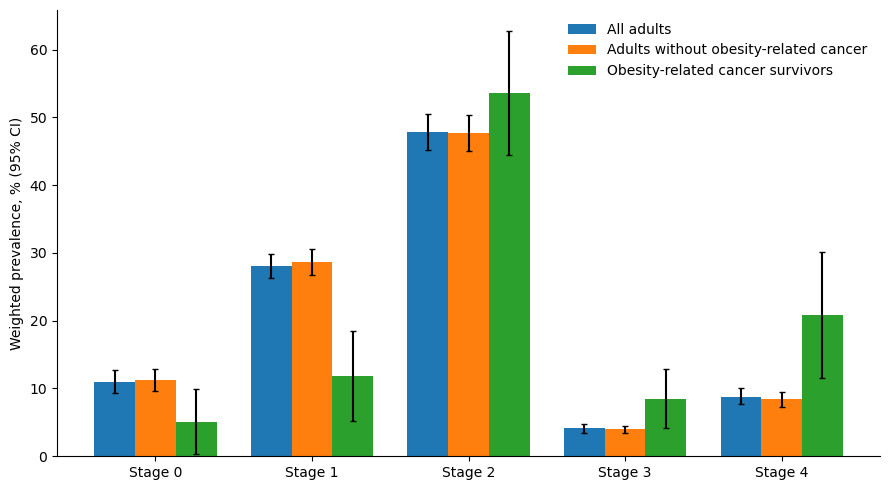

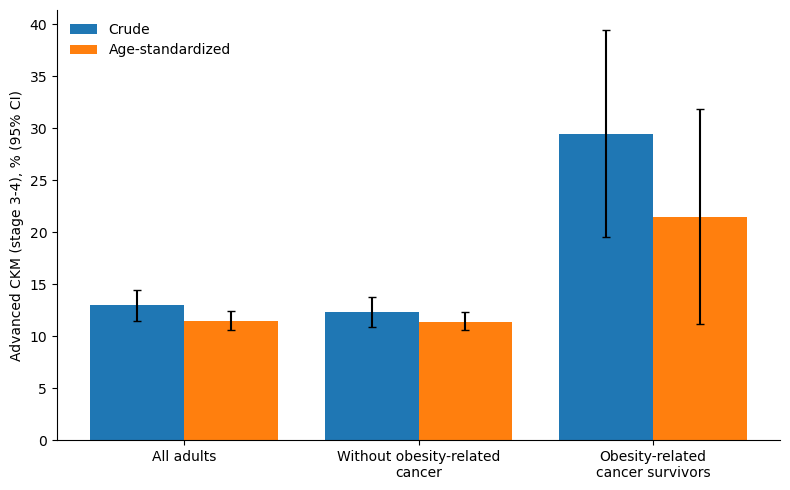

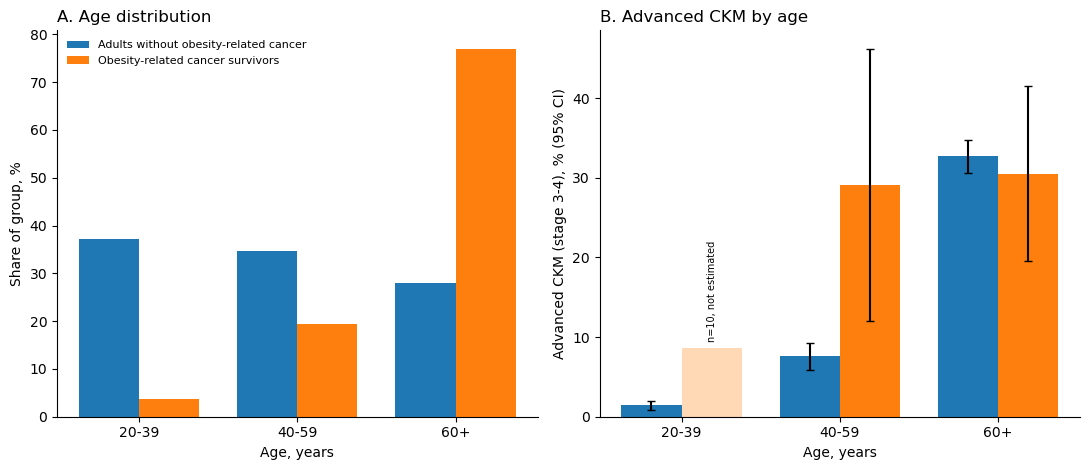

In [23]:
# figure 1: stage distribution by group
order = ["All adults", "Adults without obesity-related cancer", "Obesity-related cancer survivors"]
stages = ["Stage 0", "Stage 1", "Stage 2", "Stage 3", "Stage 4"]
fig, ax = plt.subplots(figsize=(9, 5))
wd = 0.26
for i, g in enumerate(order):
    s = stage_ci[(stage_ci.Group == g) & stage_ci.Stage.isin(stages)].set_index("Stage").loc[stages]
    err = [s["Weighted %"] - s["CI_lo"], s["CI_hi"] - s["Weighted %"]]
    ax.bar(np.arange(5) + (i - 1) * wd, s["Weighted %"], wd, yerr=err, capsize=2, label=g)
ax.set_xticks(range(5))
ax.set_xticklabels(stages)
ax.set_ylabel("Weighted prevalence, % (95% CI)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "Figure1_stage_distribution.png"), dpi=300)
plt.show()

# figure 2: advanced CKM, crude vs age-standardized
adv_ci = stage_ci[stage_ci.Stage == "Advanced (3+4)"].set_index("Group").loc[order]
sd = std_tbl.set_index("Group").loc[order]
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(3)
ax.bar(x - 0.2, adv_ci["Weighted %"], 0.4,
       yerr=[adv_ci["Weighted %"] - adv_ci["CI_lo"], adv_ci["CI_hi"] - adv_ci["Weighted %"]], capsize=3, label="Crude")
ax.bar(x + 0.2, sd["Age-standardized advanced CKM %"], 0.4,
       yerr=[sd["Age-standardized advanced CKM %"] - sd["CI_lo"], sd["CI_hi"] - sd["Age-standardized advanced CKM %"]],
       capsize=3, label="Age-standardized")
ax.set_xticks(x)
ax.set_xticklabels([o.replace("Adults without obesity-related cancer", "Without obesity-related\ncancer").replace("Obesity-related cancer survivors", "Obesity-related\ncancer survivors") for o in order])
ax.set_ylabel("Advanced CKM (stage 3-4), % (95% CI)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "Figure2_crude_vs_age_standardized.png"), dpi=300)
plt.show()

# figure 3: age distribution and advanced CKM by age band
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.8))
x = np.arange(3)
bw = 0.38
for k, gn in enumerate(G):
    s = age_tbl[age_tbl.Group == gn].reset_index(drop=True)
    a1.bar(x + (k - 0.5) * bw, s.Share, bw, label=gn)
    bars = a2.bar(x + (k - 0.5) * bw, s.Adv, bw, label=gn, color=f"C{k}")
    for j, r in s.iterrows():
        if r.n < 30:
            bars[j].set_alpha(0.3)
            a2.text(x[j] + (k - 0.5) * bw, r.Adv + 1, f"n={r.n}, not estimated", ha="center", fontsize=7, rotation=90)
        else:
            a2.errorbar(x[j] + (k - 0.5) * bw, r.Adv, yerr=[[r.Adv - r.lo], [r.hi - r.Adv]], color="black", capsize=3)
for a, yl, ti in [(a1, "Share of group, %", "A. Age distribution"),
                  (a2, "Advanced CKM (stage 3-4), % (95% CI)", "B. Advanced CKM by age")]:
    a.set_xticks(x)
    a.set_xticklabels(["20-39", "40-59", "60+"])
    a.set_xlabel("Age, years")
    a.set_ylabel(yl)
    a.set_title(ti, loc="left")
    a.spines[["top", "right"]].set_visible(False)
a1.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "Figure3_age_pattern.png"), dpi=300)
plt.show()

In [24]:
# save every reported number to one file
final = {"stage_ci": stage_ci.to_dict("records"), "prevalence_groups": prev_groups.to_dict("records"),
         "odds_ratios": or_tbl.to_dict("records"), "adjusted_comparison": adj_tbl.to_dict("records"),
         "exposure_sensitivity": sens_def.to_dict("records"), "age_standardized": std_tbl.to_dict("records"),
         "multiple_imputation": mi_res.to_dict("records"), "table3": table3.to_dict("records"),
         "age_pattern": age_tbl.to_dict("records")}
json.dump(final, open(os.path.join(OUT_DIR, "manuscript_numbers.json"), "w"), indent=2, default=str)
print("saved manuscript_numbers.json")

saved manuscript_numbers.json
